In [13]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

candidates = [
    Path.cwd(),
    Path.cwd().parent,
    Path.cwd().parent.parent,
    Path.cwd() / "Workshop_5",
    Path.cwd().parent / "Workshop_5",
]

ROOT = next(
    (
        path.resolve()
        for path in candidates
        if (path / "reports" / "metrics").is_dir()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        "file not found"
    )

METRICS_DIR = ROOT / "reports" / "metrics"
SAMPLES_DIR = ROOT / "reports" / "generated_samples"
FIGURES_DIR = ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
})

print("Workshop 5:", ROOT)
print("Figures:", FIGURES_DIR)

Workshop 5: /home/juanest/Escritorio/machineLearningWorkshop/Workshop_5
Figures: /home/juanest/Escritorio/machineLearningWorkshop/Workshop_5/reports/figures


In [14]:
gan_quality = pd.read_csv(METRICS_DIR / "gan_quality.csv")
augmentation_results = pd.read_csv(
    METRICS_DIR / "augmentation_results.csv"
)
augmentation_history = pd.read_csv(
    METRICS_DIR / "augmentation_history.csv"
)

display(gan_quality)
display(augmentation_results)
display(augmentation_history.head())

,model,unique_sequence_ratio,mean_unique_characters,character_distribution_tv,bigram_distribution_tv,unknown_charater_ratio
0,vanilla,0.051,11.933,0.398198,0.783600,0.0
1,wgan_gp,1.000,22.180,0.064790,0.315188,0.0


,condition,train_rows,best_epoch,validation_accuracy,validation_f1_macro,test_accuracy,test_f1_macro,checkpoint
0,real_only,1000000,8,0.491086,0.215557,0.492938,0.228438,C:\Users\Ruulitos\Documents\Marliton\MachineLe...
1,vanilla,1001000,8,0.488973,0.214045,0.491367,0.228740,C:\Users\Ruulitos\Documents\Marliton\MachineLe...
2,wgan_gp,1001000,8,0.485570,0.204400,0.487508,0.219600,C:\Users\Ruulitos\Documents\Marliton\MachineLe...


,condition,epoch,train_loss,val_accuracy,val_f1_macro
0,real_only,1,2.596950,0.444100,0.152382
1,real_only,2,2.364396,0.458580,0.168318
2,real_only,3,2.295001,0.463390,0.174199
3,real_only,4,2.245933,0.472677,0.185317
4,real_only,5,2.195894,0.477253,0.188923


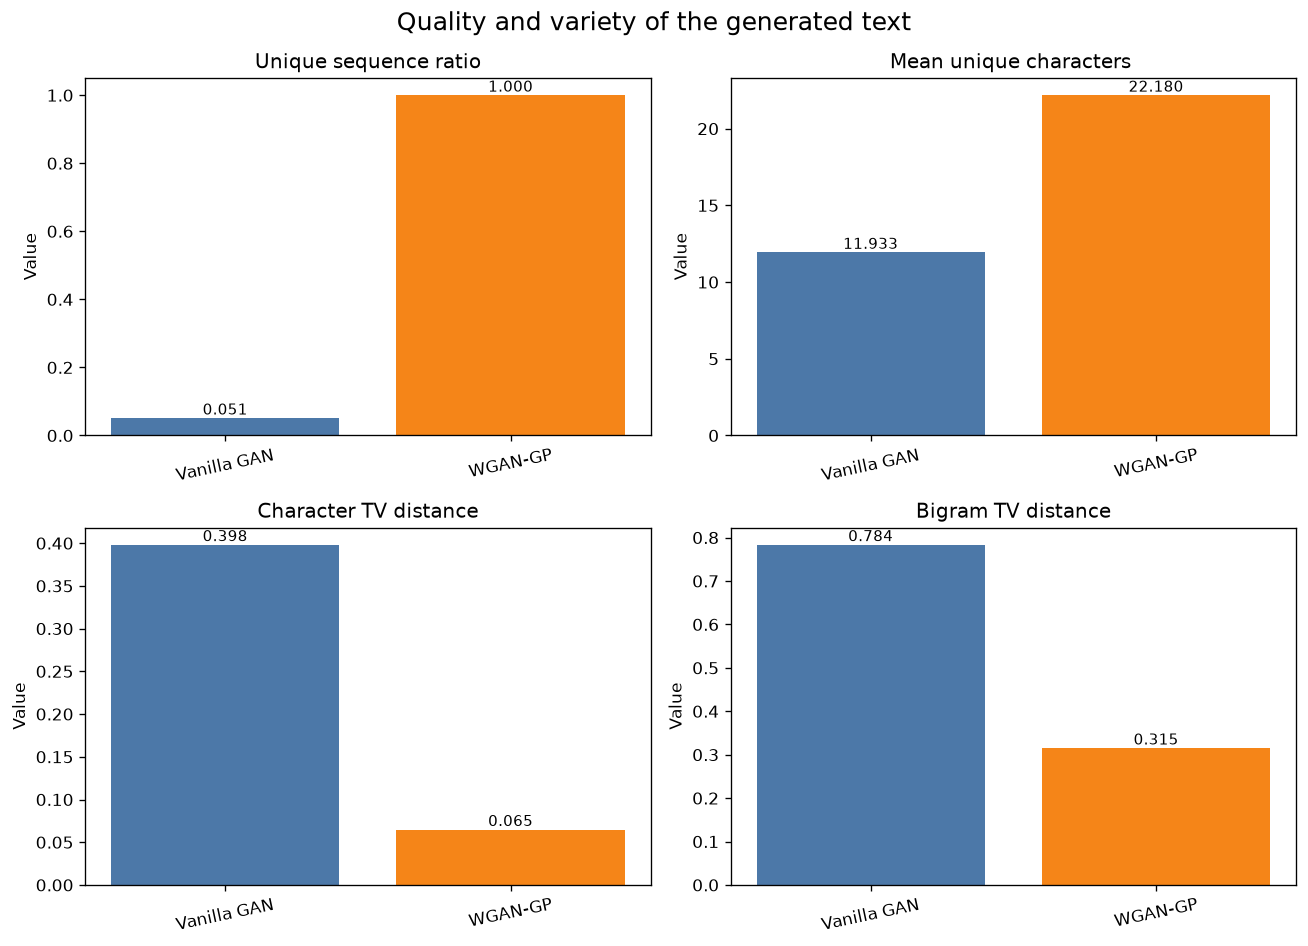

In [15]:
gan_labels = {
    "vanilla": "Vanilla GAN",
    "wgan_gp": "WGAN-GP",
}

quality_metrics = [
    ("unique_sequence_ratio", "Unique sequence ratio"),
    ("mean_unique_characters", "Mean unique characters "),
    ("character_distribution_tv", "Character TV distance"),
    ("bigram_distribution_tv", "Bigram TV distance"),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes = axes.ravel()

for ax, (column, title) in zip(axes, quality_metrics):
    values = gan_quality.set_index("model")[column]
    labels = [gan_labels.get(model, model) for model in values.index]
    bars = ax.bar(labels, values.values, color=["#4C78A8", "#F58518"])

    ax.set_title(title)
    ax.set_ylabel("Value")
    ax.tick_params(axis="x", rotation=12)

    for bar, value in zip(bars, values.values):
        ax.annotate(
            f"{value:.3f}",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            ha="center",
            va="bottom",
            fontsize=9,
        )

fig.suptitle("Quality and variety of the generated text", fontsize=15)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "gan_quality_metrics.png", bbox_inches="tight")
plt.show()


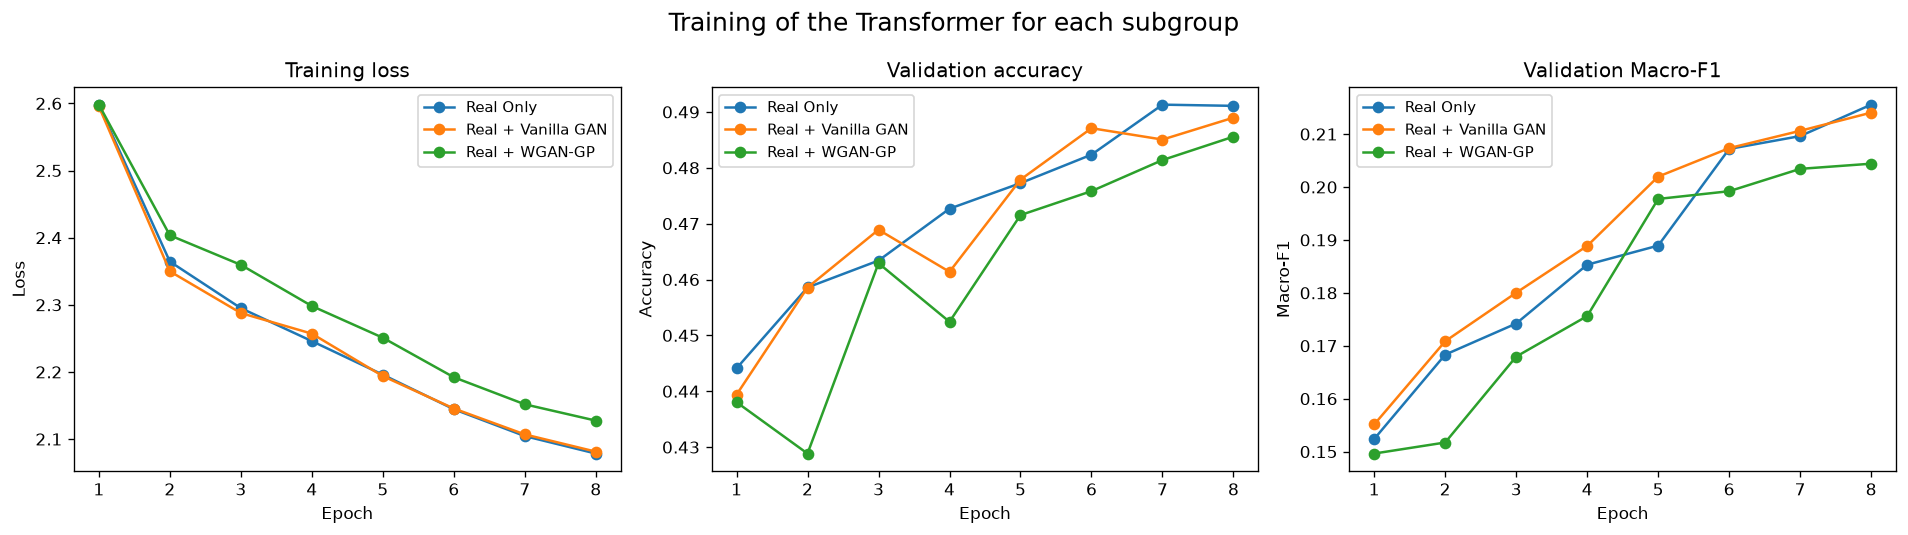

In [16]:

condition_labels = {
    "real_only": "Real Only",
    "vanilla": "Real + Vanilla GAN",
    "wgan_gp": "Real + WGAN-GP",
}

history_metrics = [
    ("train_loss", "Training loss", "Loss"),
    ("val_accuracy", "Validation accuracy", "Accuracy"),
    ("val_f1_macro", "Validation Macro-F1", "Macro-F1"),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (column, title, ylabel) in zip(axes, history_metrics):
    for condition in ["real_only", "vanilla", "wgan_gp"]:
        subset = augmentation_history[
            augmentation_history["condition"] == condition
        ].sort_values("epoch")

        ax.plot(
            subset["epoch"],
            subset[column],
            marker="o",
            label=condition_labels.get(condition, condition),
        )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.legend()

fig.suptitle("Training of the Transformer for each subgroup", fontsize=15)
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "augmentation_learning_curves.png",
    bbox_inches="tight",
)
plt.show()

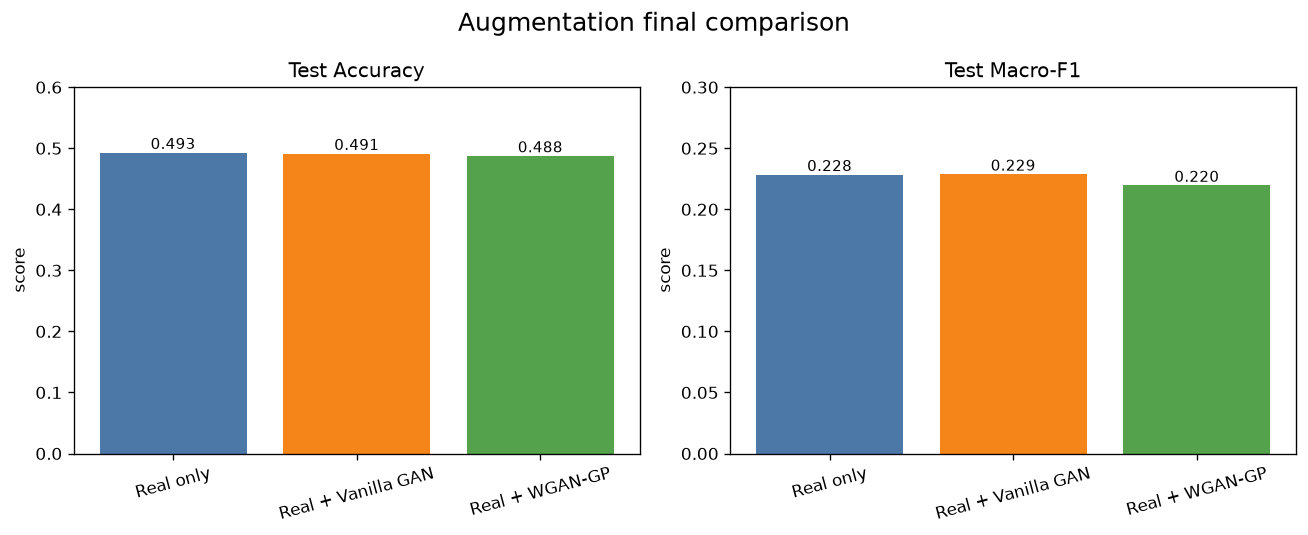

In [17]:

model_labels = {
    "real_only": "Real only",
    "vanilla": "Real + Vanilla GAN",
    "wgan_gp": "Real + WGAN-GP",
}

plot_data = augmentation_results.copy()
plot_data["label"] = plot_data["condition"].map(model_labels)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, metric, title, upper_limit in [
    (axes[0], "test_accuracy", "Test Accuracy", 0.60),
    (axes[1], "test_f1_macro", "Test Macro-F1", 0.30),
]:
    bars = ax.bar(
        plot_data["label"],
        plot_data[metric],
        color=["#4C78A8", "#F58518", "#54A24B"],
    )
    ax.set_title(title)
    ax.set_ylabel("score")
    ax.set_ylim(0, upper_limit)
    ax.tick_params(axis="x", rotation=15)

    for bar, value in zip(bars, plot_data[metric]):
        ax.annotate(
            f"{value:.3f}",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            ha="center",
            va="bottom",
            fontsize=9,
        )

fig.suptitle("Augmentation final comparison", fontsize=15)
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "augmentation_test_comparison.png",
    bbox_inches="tight",
)
plt.show()